# IMDb Top 700: What Makes a Movie Timeless?
### Exploratory Data Analysis (EDA)

**What is this project about?**

IMDb keeps a list of the 700 highest-rated movies. The Content Insights team wants to know **why** these movies
score so well. Is it their genre? The decade they were made in? The director? The country? The number of votes?


**Steps in this notebook**

| Step | Topic |
|---|---|
| 1 | Understanding the problem and the key metric |
| 2 | Hypotheses |
| 3 | Importing libraries |
| 4 | Loading data |
| 5 | Inspecting data |
| 6 | Checking missing values and duplicates |
| 7 | Cleaning and preparing the data |
| 8 | Finding and handling the outliers |
| 9 | Normalising values |
| 10 | Overall numbers (KPIs) |
| 11 | Genre analysis |
| 12 | Decade analysis |
| 13 | Director analysis |
| 14 | Actor analysis |
| 15 | Country analysis |
| 16 | Votes and runtime vs rating |
| 17 | Correlation heatmap |
| 18 | Testing hypotheses |
| 19 | Key insights and recommendations |


## Step 1: Understanding the problem and the key metric

**Business question:** which factors (genre, era, director, country, votes, runtime) are linked to a movie getting a
**high rating** in the IMDb Top 700?

**Key metric:** **Average IMDb Rating** = the mean (average) of the `IMDb Rating` column for a group of movies.
For example, "the average rating of all War movies".

**Supporting KPIs (Key Performance Indicators):**

| KPI | How we calculate it | What it tells us |
|---|---|---|
| Average Votes per Film | mean of `Votes`, by genre and by decade | Is a high rating backed by many people or only a few fans? |
| Director Frequency | number of Top 700 films per director | Which directors make great films again and again? |
| Country Representation Rate | films per country ÷ 700 | Which countries appear most in the list? |

**Breaking the key metric into smaller parts.** Will look at the average rating from six angles:

```
Average IMDb Rating
 ├── by Genre      (Drama, Action, Comedy ...)
 ├── by Decade     (1950s, 1990s, 2010s ...)
 ├── by Director   (how many Top 700 films they have)
 ├── by Actor      (famous repeat actors or not)
 ├── by Country    (country listed in the data)
 └── by Votes and Runtime (number of votes, movie length)
```

## Step 2: Hypotheses


|   | Hypothesis |
|---|---|
| H1 | Movies with **more votes** have **higher ratings** |
| H2 | **Longer** movies have **higher ratings** |
| H3 | **Drama** movies rate higher than non-Drama movies |
| H4 | **Older** movies (before 1980) rate higher than **newer** movies (2000 onwards) |
| H5 | Directors with **4 or more** Top 700 films have higher ratings than directors with only 1 |
| H6 | Movies with a **famous repeat actor** (5+ Top 700 films) rate higher |
| H7 | The average rating is **different between countries** |

## Step 3: Importing the libraries


| Library | What it does |
|---|---|
| `pandas` | Works with tables of data (like Excel in Python) |
| `numpy` | Maths on numbers |
| `matplotlib` and `seaborn` | Draw charts |
| `scipy.stats` | Statistical tests (t-test, ANOVA) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')            # hide warning messages to keep the output clean

# Chart settings: one main colour and readable text for every chart
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#c9c8c1'
plt.rcParams.update({'figure.figsize': (6.5, 4), 'font.size': 12, 'axes.titlesize': 13,
                     'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.float_format', '{:.2f}'.format)    # show numbers with 2 decimals
import os
os.makedirs('figures', exist_ok=True)                     # folder to save chart images
print('Libraries loaded')

Libraries loaded


## Step 4: Loading data

Read the CSV file into a pandas table (called a **DataFrame**).



In [2]:
FILE_NAME = 'IMDb_Top_700_Movies_2026.csv'
DRIVE_LINK = 'https://drive.google.com/uc?export=download&id=1WZ-nnB5fDSaFgjJoXaBSyQV8jRvMGOEa'

if os.path.exists(FILE_NAME):
    df = pd.read_csv(FILE_NAME)          # use the uploaded file
else:
    df = pd.read_csv(DRIVE_LINK)         # read from Google Drive

df.head()                                # show the first 5 rows

,Rank,Title,Year,Genre(s),Director,Main Actor(s),Country,IMDb Rating,Votes,Runtime (mins)
0,1,The Shawshank Redemption,1994,Drama,Frank Darabont,Tim Robbins|Morgan Freeman|Bob Gunton,DK|AT,9.30,3219532,142
1,2,The Godfather,1972,Crime|Drama,Francis Ford Coppola,Marlon Brando|Al Pacino|James Caan,DK|AT,9.20,2244476,175
2,3,The Dark Knight,2008,Crime|Thriller,Christopher Nolan,Christian Bale|Heath Ledger|Aaron Eckhart,DK|LV,9.10,3205233,152
3,4,The Lord of the Rings: The Return of the King,2003,Adventure|Drama|Fantasy,Peter Jackson,Elijah Wood|Viggo Mortensen|Ian McKellen,DK|MK,9.00,2181911,201
4,5,Schindler's List,1993,Biography|Drama|History,Steven Spielberg,Liam Neeson|Ralph Fiennes|Ben Kingsley,DK|LV,9.00,1595992,195


## Step 5: Inspecting data

**What:** look at the size, column types and basic statistics.

**Why:** to understand what each column contains before we change anything.

In [3]:
print('Rows and columns:', df.shape)     # (number of rows, number of columns)
df.info()                                # column names, data types and non-empty counts

Rows and columns: (700, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Rank            700 non-null    int64  
 1   Title           700 non-null    object 
 2   Year            700 non-null    int64  
 3   Genre(s)        700 non-null    object 
 4   Director        700 non-null    object 
 5   Main Actor(s)   690 non-null    object 
 6   Country         700 non-null    object 
 7   IMDb Rating     700 non-null    float64
 8   Votes           700 non-null    int64  
 9   Runtime (mins)  700 non-null    int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 54.8+ KB


In [4]:
df.describe()                            # count, mean, min, max etc. for the number columns

,Rank,Year,IMDb Rating,Votes,Runtime (mins)
count,700.00,700.00,700.00,700.00,700.00
mean,350.50,1998.04,8.00,533097.34,127.36
std,202.22,21.35,0.32,469272.25,29.10
min,1.00,1921.00,7.50,51964.00,68.00
25%,175.75,1989.00,7.80,198261.00,106.00
50%,350.50,2004.00,8.00,398847.50,123.00
75%,525.25,2013.25,8.20,728513.00,143.00
max,700.00,2026.00,9.30,3219532.00,321.00


**Observations :**
* The data has **700 movies** and **10 columns**.
* `Year`, `IMDb Rating`, `Votes` and `Runtime (mins)` are numbers. The other columns are text.
* Ratings go from **7.5 to 9.3**, average **8.00**. All movies are already very good, so differences between
  groups will be small (for example 0.1 points).
* Votes go from **52 thousand to 3.2 million**. That is a very wide range.
* `Genre(s)`, `Director`, `Main Actor(s)` and `Country` can hold **several values** separated by `|`
  (for example `Crime|Drama`).

## Step 6: Checking missing values and duplicates
### 6.1 Missing values
**What:** count empty cells in each column. **Why:** empty cells can break calculations.

In [5]:
df.isnull().sum()                        # number of empty cells per column

,0
Rank,0
Title,0
Year,0
Genre(s),0
Director,0
Main Actor(s),10
Country,0
IMDb Rating,0
Votes,0
Runtime (mins),0


In [6]:
df[df['Main Actor(s)'].isnull()][['Title', 'Year', 'Genre(s)']]   # which movies have no actors?

,Title,Year,Genre(s)
426,Senna,2010,Biography|Documentary|Sport
446,20 Days in Mariupol,2023,Documentary|War
518,Bowling for Columbine,2002,Crime|Documentary|Drama
534,Kill Bill: The Whole Bloody Affair,2004,Action|Crime|Thriller
556,Inside Job,2010,Crime|Documentary
592,Free Solo,2018,Adventure|Documentary|Sport
593,Searching for Sugar Man,2012,Biography|Documentary|Music
611,Flow,2024,Adventure|Animation|Family
671,Blackfish,2013,Documentary|Drama|Thriller
696,The Cove,2009,Biography|Crime|Documentary


Only **10 movies** have no actors listed. Most are **documentaries** (real-life films with no actors), so this is
normal. We filled them with the text **"Not listed"** instead of deleting them.

### 6.2 Duplicates
**What:** check for repeated rows. **Why:** a repeated movie would be counted twice.

In [7]:
print('Fully repeated rows:', df.duplicated().sum())
print('Repeated titles    :', df['Title'].duplicated().sum())
df[df['Title'].duplicated(keep=False)][['Title', 'Year', 'Director']]

Fully repeated rows: 0
Repeated titles    : 1


,Title,Year,Director
324,The Girl with the Dragon Tattoo,2011,David Fincher
472,The Girl with the Dragon Tattoo,2009,Niels Arden Oplev


No repeated rows. One title appears twice, but they are **two different movies** (2009 and 2011 versions with
different directors), so **keep both**.

### 6.3 Repeated names inside one cell
Some movies list the same actor twice, for example *"Robert Pattinson|Robert Pattinson|Zoë Kravitz"*.

In [8]:
def has_repeated_actor(text):
    names = str(text).split('|')
    return len(names) != len(set(names))      # set() removes repeats, so lengths differ if a name repeats

print('Movies with a repeated actor name:', df['Main Actor(s)'].apply(has_repeated_actor).sum())

Movies with a repeated actor name: 74


**74 movies** have a repeated actor name. We remove the repeats so actors are not counted twice.

## Step 7: Cleaning and preparing the data

**What we do, and why:**

| Action | Why |
|---|---|
| Rename columns to short names | Easier to type (`Rating` instead of `IMDb Rating`) |
| Fill missing actors with "Not listed" | No empty cells |
| Remove repeated actor names | Count each actor once |
| Add a `Decade` column (1994 → 1990) | Group movies by era |
| Split `Genres`, `Director`, `Actors` into lists | One movie can have several of each |
| Add `Main_Director` (first director listed) | One director per movie for simple grouping |
| Turn country codes into names (DK → Denmark) | Easier to read |

In [9]:
# 1. Rename columns
df = df.rename(columns={'IMDb Rating': 'Rating', 'Runtime (mins)': 'Runtime',
                        'Genre(s)': 'Genres', 'Main Actor(s)': 'Actors'})

# 2. Fill missing actors
df['Actors'] = df['Actors'].fillna('Not listed')

# 3. Remove repeated actor names (dict.fromkeys keeps the first copy of each name, in order)
df['Actors'] = df['Actors'].apply(lambda text: '|'.join(dict.fromkeys(text.split('|'))))

# 4. Decade: 1994 // 10 = 199, then * 10 = 1990
df['Decade'] = (df['Year'] // 10) * 10

# 5. Split multi-value columns into Python lists
df['Genre_List'] = df['Genres'].str.split('|')
df['Director_List'] = df['Director'].str.split('|')
df['Actor_List'] = df['Actors'].str.split('|')

# 6. Main director = the first name in the list
df['Main_Director'] = df['Director_List'].str[0]

# 7. Country codes -> country names (the first code is the "main" country)
country_names = {'DK': 'Denmark', 'LV': 'Latvia', 'PH': 'Philippines', 'AT': 'Austria', 'PT': 'Portugal',
                 'ZA': 'South Africa', 'MK': 'North Macedonia', 'CR': 'Costa Rica', 'AU': 'Australia',
                 'LU': 'Luxembourg', 'NZ': 'New Zealand', 'NO': 'Norway', 'AR': 'Argentina', 'FR': 'France',
                 'PL': 'Poland', 'US': 'United States', 'HN': 'Honduras', 'DO': 'Dominican Republic', 'IN': 'India'}
df['Main_Country'] = df['Country'].str.split('|').str[0].map(country_names)

print('Missing values left:', df.isnull().sum().sum())
df[['Title', 'Year', 'Decade', 'Rating', 'Main_Director', 'Main_Country']].head()

Missing values left: 0


,Title,Year,Decade,Rating,Main_Director,Main_Country
0,The Shawshank Redemption,1994,1990,9.30,Frank Darabont,Denmark
1,The Godfather,1972,1970,9.20,Francis Ford Coppola,Denmark
2,The Dark Knight,2008,2000,9.10,Christopher Nolan,Denmark
3,The Lord of the Rings: The Return of the King,2003,2000,9.00,Peter Jackson,Denmark
4,Schindler's List,1993,1990,9.00,Steven Spielberg,Denmark


### A note on the Country column
When we check famous movies, the country codes look **wrong**:

In [10]:
df[df['Title'].isin(['The Shawshank Redemption', 'Parasite', 'Seven Samurai', '3 Idiots'])][['Title', 'Country', 'Main_Country']]

,Title,Country,Main_Country
0,The Shawshank Redemption,DK|AT,Denmark
37,Parasite,DK|LV,Denmark
55,Seven Samurai,DK|PT,Denmark
77,3 Idiots,LV|PH,Latvia


*The Shawshank Redemption* is an American film but is listed as Denmark + Austria. *Parasite* is Korean but is listed
as Denmark + Latvia. So the `Country` column **does not show where a movie was made**.

### Making "long" tables for genres, directors and actors
One movie can have 3 genres. To count genres properly we use `explode()`, which gives **one row per genre**.

Example: *The Godfather* with `['Crime', 'Drama']` becomes 2 rows: one for Crime and one for Drama.

In [11]:
genre_df = df.explode('Genre_List').rename(columns={'Genre_List': 'Genre'})
director_df = df.explode('Director_List').rename(columns={'Director_List': 'Director_Name'})
actor_df = df[df['Actors'] != 'Not listed'].explode('Actor_List').rename(columns={'Actor_List': 'Actor'})

print('Rows in movie table   :', len(df))
print('Rows in genre table   :', len(genre_df))
print('Rows in director table:', len(director_df))
print('Rows in actor table   :', len(actor_df))

Rows in movie table   : 700
Rows in genre table   : 1823
Rows in director table: 776
Rows in actor table   : 1986


## Step 8: Finding and handling the outliers


**How we find them (IQR rule):**
* Q1 = the value 25% of the way up the data, Q3 = the value 75% of the way up. IQR = Q3 − Q1.
* Anything below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR** is an outlier.

A **box plot** shows this. The dots outside the "whiskers" are outliers.

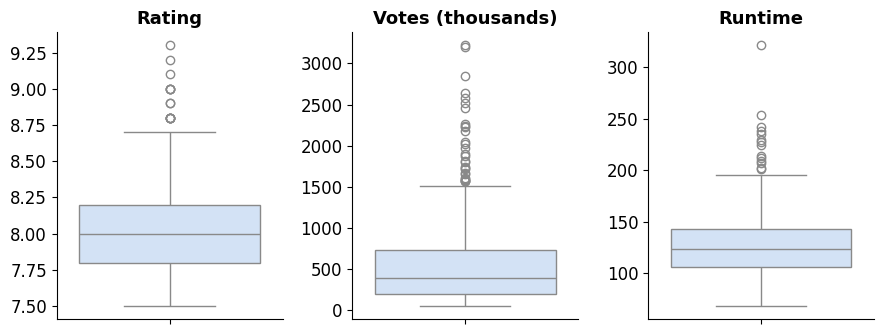

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3.5))
for ax, column in zip(axes, ['Rating', 'Votes', 'Runtime']):
    values = df[column] / 1000 if column == 'Votes' else df[column]     # show votes in thousands
    sns.boxplot(y=values, ax=ax, color='#cde2fb')
    ax.set_title('Votes (thousands)' if column == 'Votes' else column)
    ax.set_ylabel('')
plt.tight_layout()
plt.savefig('figures/01_outliers.png', dpi=200, bbox_inches='tight')
plt.show()

In [13]:
for column in ['Rating', 'Votes', 'Runtime']:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[column] < Q1 - 1.5 * IQR) | (df[column] > Q3 + 1.5 * IQR)]
    print(f'{column}: {len(outliers)} outliers, e.g. {list(outliers["Title"].head(3))}')

Rating: 15 outliers, e.g. ['The Shawshank Redemption', 'The Godfather', 'The Dark Knight']
Votes: 29 outliers, e.g. ['The Shawshank Redemption', 'The Godfather', 'The Dark Knight']
Runtime: 14 outliers, e.g. ['The Lord of the Rings: The Return of the King', 'The Godfather Part II', 'Seven Samurai']


**Decision: we keep all outliers.** They are not mistakes. They are the most famous movies (*The Shawshank
Redemption*, *The Godfather*), the most-voted movies, and genuinely long epics (*Gangs of Wasseypur*, 321 minutes).
Removing them would remove the very movies we want to understand. Instead, we will be careful when reading averages.

## Step 9: Normalising values

**What:** rescale `Votes` and `Runtime` to a **0 to 1** scale (min-max normalisation).

**Why:** votes are in millions and runtime is in minutes. On a 0–1 scale we can compare them side by side.

**Formula:** normalised value = (value − minimum) ÷ (maximum − minimum)

In [14]:
df['Votes_Normalised'] = (df['Votes'] - df['Votes'].min()) / (df['Votes'].max() - df['Votes'].min())
df['Runtime_Normalised'] = (df['Runtime'] - df['Runtime'].min()) / (df['Runtime'].max() - df['Runtime'].min())
df['Votes_K'] = df['Votes'] / 1000          # votes in thousands, easier to read

df[['Title', 'Votes', 'Votes_Normalised', 'Runtime', 'Runtime_Normalised']].head()

,Title,Votes,Votes_Normalised,Runtime,Runtime_Normalised
0,The Shawshank Redemption,3219532,1.00,142,0.29
1,The Godfather,2244476,0.69,175,0.42
2,The Dark Knight,3205233,1.00,152,0.33
3,The Lord of the Rings: The Return of the King,2181911,0.67,201,0.53
4,Schindler's List,1595992,0.49,195,0.50


The most-voted movie now has 1.0 and the least-voted has 0.0. The same holds for runtime.

## Step 10: Overall numbers (KPIs)

In [15]:
print('Number of movies         :', len(df))
print('Average IMDb Rating      :', round(df['Rating'].mean(), 2))
print('Average Votes per Film   :', f"{df['Votes'].mean():,.0f}")
print('Average Runtime (minutes):', round(df['Runtime'].mean(), 1))
print('Number of directors      :', director_df['Director_Name'].nunique())
print('Year range               :', df['Year'].min(), 'to', df['Year'].max())

Number of movies         : 700
Average IMDb Rating      : 8.0
Average Votes per Film   : 533,097
Average Runtime (minutes): 127.4
Number of directors      : 448
Year range               : 1921 to 2026


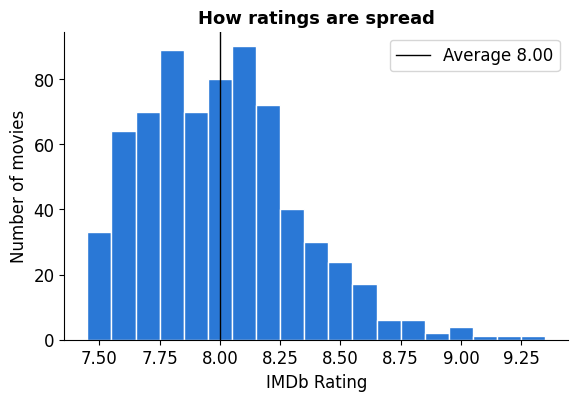

In [16]:
plt.hist(df['Rating'], bins=np.arange(7.45, 9.4, 0.1), color=BLUE, edgecolor='white')
plt.axvline(df['Rating'].mean(), color='black', linewidth=1, label='Average 8.00')
plt.title('How ratings are spread')
plt.xlabel('IMDb Rating'); plt.ylabel('Number of movies'); plt.legend()
plt.savefig('figures/02_rating_histogram.png', dpi=200, bbox_inches='tight')
plt.show()

**Observation :** most movies are rated between **7.6 and 8.2**. Only a handful score 8.8 or more (the
all-time classics).

## Step 11: Genre analysis

**What:** for each genre, count the movies and calculate the average rating and average votes.

**How:** `groupby('Genre')` puts all movies of the same genre together, and `.agg()` calculates the numbers.
We only rank genres with **at least 10 movies**, because an average of 7 movies is not reliable.

In [17]:
genre_table = genre_df.groupby('Genre').agg(
    Movies=('Title', 'count'),
    Avg_Rating=('Rating', 'mean'),
    Avg_Votes=('Votes', 'mean'))
genre_table = genre_table[genre_table['Movies'] >= 10].sort_values('Avg_Rating', ascending=False)
genre_table

,Movies,Avg_Rating,Avg_Votes
Genre,,,
War,32,8.18,473960.28
Western,13,8.12,490463.38
Biography,78,8.04,426798.15
Drama,473,8.03,480990.64
Animation,63,8.02,500848.05
Crime,156,8.01,549694.29
Music,16,8.01,392191.12
Sport,16,7.99,343668.00
Sci-Fi,62,7.99,878560.42


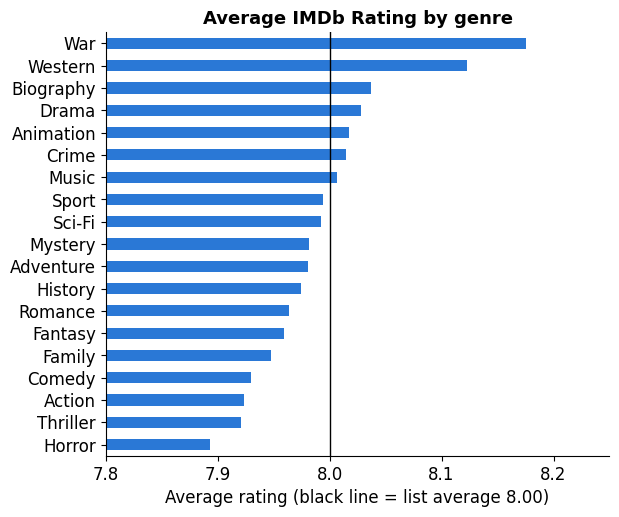

In [18]:
genre_table['Avg_Rating'].sort_values().plot(kind='barh', color=BLUE, figsize=(6.5, 5.5))
plt.axvline(df['Rating'].mean(), color='black', linewidth=1)
plt.xlim(7.8, 8.25)
plt.title('Average IMDb Rating by genre')
plt.xlabel('Average rating (black line = list average 8.00)'); plt.ylabel('')
plt.savefig('figures/03_genre_rating.png', dpi=200, bbox_inches='tight')
plt.show()

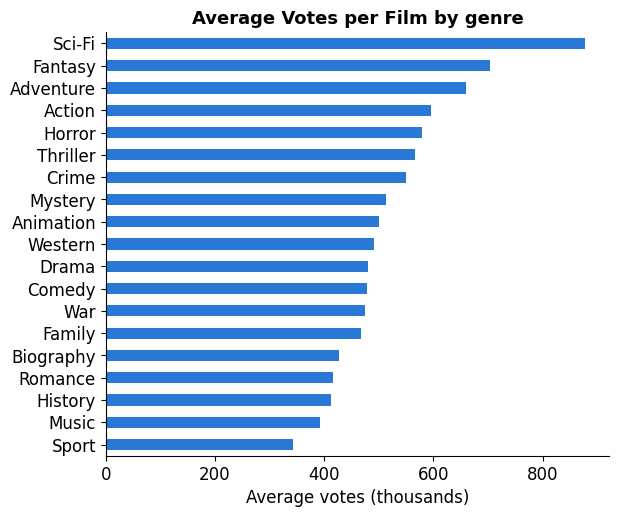

In [19]:
(genre_table['Avg_Votes'] / 1000).sort_values().plot(kind='barh', color=BLUE, figsize=(6.5, 5.5))
plt.title('Average Votes per Film by genre')
plt.xlabel('Average votes (thousands)'); plt.ylabel('')
plt.savefig('figures/04_genre_votes.png', dpi=200, bbox_inches='tight')
plt.show()

**Observations :**
* **Highest rated:** War (8.18), Western (8.12), Biography (8.04) and Drama (8.03).
* **Lowest rated:** Horror (7.89), Thriller (7.92), Action (7.92) and Comedy (7.93).
* **Drama** is in 473 of the 700 movies (68%). It is the most common genre by far.
* **Most votes per film:** Sci-Fi (879K), Fantasy (704K) and Adventure (659K). Big "spectacle" movies attract huge
  audiences, while serious genres like War and Biography get **higher ratings with fewer votes**.

## Step 12: Decade analysis
**What:** the same calculation, grouped by `Decade`.

In [20]:
decade_table = df.groupby('Decade').agg(
    Movies=('Title', 'count'),
    Avg_Rating=('Rating', 'mean'),
    Avg_Votes=('Votes', 'mean'))
decade_table

,Movies,Avg_Rating,Avg_Votes
Decade,,,
1920,5,8.08,141474.40
1930,8,8.18,250776.50
1940,14,8.17,248892.79
1950,29,8.17,238831.69
1960,31,8.14,273036.26
1970,34,8.09,524364.76
1980,61,8.01,478850.72
1990,95,8.06,702084.31
2000,177,7.92,608729.33


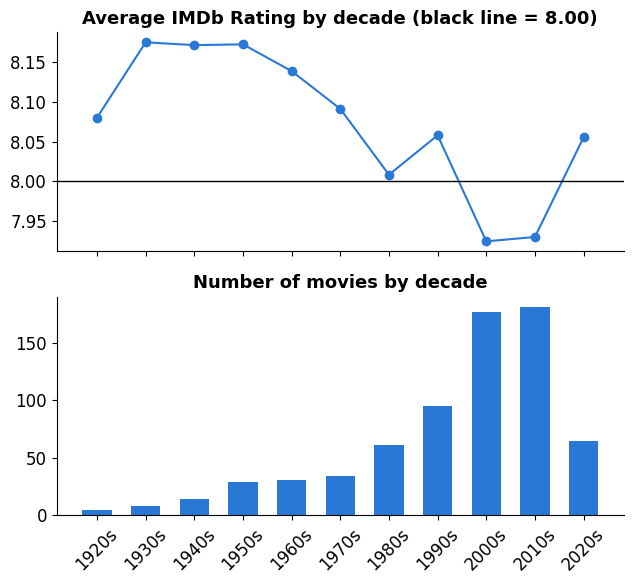

In [21]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 6), sharex=True)
ax1.plot(decade_table.index, decade_table['Avg_Rating'], marker='o', color=BLUE)
ax1.axhline(df['Rating'].mean(), color='black', linewidth=1)
ax1.set_title('Average IMDb Rating by decade (black line = 8.00)')
ax2.bar(decade_table.index, decade_table['Movies'], width=6, color=BLUE)
ax2.set_title('Number of movies by decade')
ax2.set_xticks(decade_table.index)
ax2.set_xticklabels([f'{d}s' for d in decade_table.index], rotation=45)
plt.tight_layout()
plt.savefig('figures/05_decade.png', dpi=200, bbox_inches='tight')
plt.show()

**Observations :**
* **Old movies rate highest:** 1930s to 1960s movies average **8.14 to 8.18**. Only the very best old films are
  still remembered and voted for today, so the old movies that remain in the list are all excellent.
* **2000s and 2010s** have the most movies (358 together, 51% of the list) but the **lowest averages (7.92–7.93)**.
  Many "very good" modern movies made it in.
* **2020s** movies average 8.06, but they are new. Their ratings may still go down as more people vote.

### Average Votes per Film by Genre and Decade (supporting KPI)
A **pivot table** puts genres in rows, decades in columns and the average votes in each cell. A **heatmap** colours
the cells: darker = more votes.

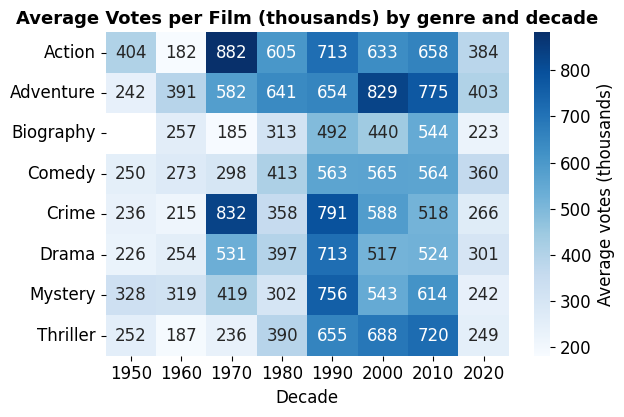

In [22]:
main_genres = genre_table.sort_values('Movies', ascending=False).index[:8]      # 8 biggest genres
pivot = genre_df[genre_df['Genre'].isin(main_genres) & (genre_df['Decade'] >= 1950)].pivot_table(
    index='Genre', columns='Decade', values='Votes', aggfunc='mean') / 1000
plt.figure(figsize=(6.5, 4.2))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': 'Average votes (thousands)'})
plt.title('Average Votes per Film (thousands) by genre and decade')
plt.xlabel('Decade'); plt.ylabel('')
plt.savefig('figures/06_genre_decade_votes.png', dpi=200, bbox_inches='tight')
plt.show()

Movies from the **1990s to 2010s** have the most votes in almost every genre. These are the years when today's
IMDb users grew up. Older movies have high ratings but **fewer votes**.

## Step 13: Director analysis
### 13.1 Director Frequency (KPI)
**What:** count how many Top 700 movies each director has. `value_counts()` counts each name.

In [23]:
director_counts = director_df['Director_Name'].value_counts()
print('Number of directors:', len(director_counts))
print('Directors with only 1 film:', (director_counts == 1).sum())
director_counts.head(10)

Number of directors: 448
Directors with only 1 film: 303


,count
Director_Name,
Steven Spielberg,12
Martin Scorsese,11
Christopher Nolan,10
Stanley Kubrick,10
Quentin Tarantino,10
Alfred Hitchcock,9
David Fincher,8
Hayao Miyazaki,7
Clint Eastwood,7


Steven Spielberg (12), Martin Scorsese (11), and Christopher Nolan, Quentin Tarantino and Stanley Kubrick (10 each)
appear most often.

### 13.2 Which repeat directors have the highest ratings?

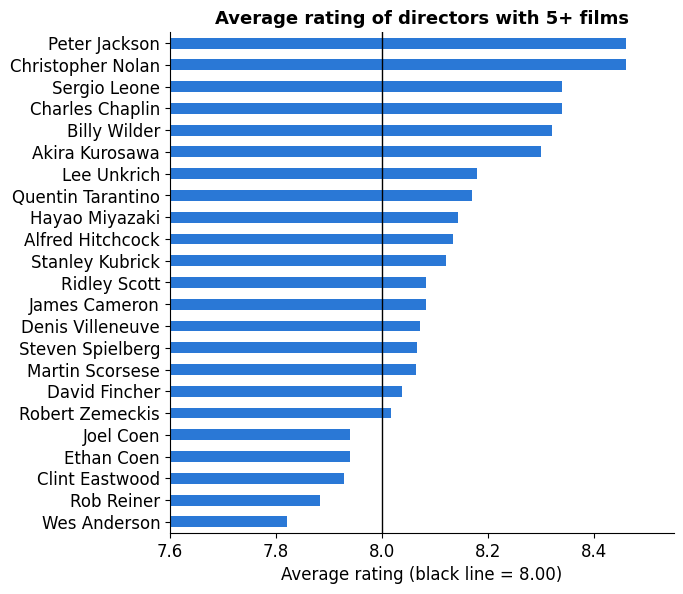

In [24]:
director_table = director_df.groupby('Director_Name').agg(Movies=('Title', 'count'), Avg_Rating=('Rating', 'mean'))
top_directors = director_table[director_table['Movies'] >= 5].sort_values('Avg_Rating')
top_directors['Avg_Rating'].plot(kind='barh', color=BLUE, figsize=(6.5, 6.5))
plt.axvline(df['Rating'].mean(), color='black', linewidth=1)
plt.xlim(7.6, 8.55)
plt.title('Average rating of directors with 5+ films')
plt.xlabel('Average rating (black line = 8.00)'); plt.ylabel('')
plt.savefig('figures/07_top_directors.png', dpi=200, bbox_inches='tight')
plt.show()

### 13.3 Does a director's track record matter?
Give every movie the number of Top 700 films its main director has, then put movies into 3 groups.

In [25]:
df['Director_Films'] = df['Main_Director'].map(director_counts)
df['Director_Group'] = pd.cut(df['Director_Films'], bins=[0, 1, 3, 100], labels=['1 film', '2-3 films', '4+ films'])
df['In_Top_100'] = df['Rank'] <= 100

director_group_table = df.groupby('Director_Group').agg(
    Movies=('Title', 'count'),
    Avg_Rating=('Rating', 'mean'),
    Avg_Votes=('Votes', 'mean'),
    Percent_in_Top_100=('In_Top_100', 'mean'))
director_group_table['Percent_in_Top_100'] *= 100
director_group_table

,Movies,Avg_Rating,Avg_Votes,Percent_in_Top_100
Director_Group,,,,
1 film,254,7.98,387167.16,7.48
2-3 films,222,7.96,485906.35,10.81
4+ films,224,8.06,745341.38,25.45


**Observations :**
* Movies by directors with **4+ films** average **8.06**, compared with 7.98 for one-time directors.
* The bigger difference is at the very top: **25% of their movies are in the Top 100**, compared with only 7.5%
  for one-time directors (more than 3 times as likely).
* Best repeat directors: Peter Jackson and Christopher Nolan (8.46), then Charles Chaplin, Sergio Leone,
  Billy Wilder and Akira Kurosawa (8.30–8.34).

## Step 14: Actor analysis
**What:** count the Top 700 movies of each actor, then check whether movies with a **famous repeat actor**
(5 or more Top 700 movies) rate higher.

In [26]:
actor_counts = actor_df['Actor'].value_counts()
actor_counts.head(10)

,count
Actor,
Robert De Niro,16
Leonardo DiCaprio,14
Tom Hanks,14
Al Pacino,12
Brad Pitt,11
Tom Cruise,11
Matt Damon,11
Emma Watson,10
Christian Bale,10


In [27]:
famous_actors = set(actor_counts[actor_counts >= 5].index)       # actors with 5+ films
df['Has_Famous_Actor'] = df['Actor_List'].apply(lambda names: any(name in famous_actors for name in names))

actor_group_table = df.groupby('Has_Famous_Actor').agg(
    Movies=('Title', 'count'), Avg_Rating=('Rating', 'mean'), Avg_Votes=('Votes', 'mean'))
actor_group_table

,Movies,Avg_Rating,Avg_Votes
Has_Famous_Actor,,,
False,460,8.00,419996.39
True,240,8.00,749874.16


**Observations :**
* Robert De Niro (16), Leonardo DiCaprio and Tom Hanks (14) and Al Pacino (12) appear most often.
* Movies with a famous repeat actor get **many more votes** (750K vs 420K on average) but **almost the same rating**
  (8.00 vs 8.00). Famous actors bring **bigger audiences**, not higher ratings.

## Step 15: Country analysis (as listed in the data)
**Country Representation Rate** = number of movies per country ÷ 700. `value_counts(normalize=True)` gives this
directly.

In [28]:
country_rate = df['Main_Country'].value_counts(normalize=True) * 100
country_table = pd.DataFrame({
    'Movies': df['Main_Country'].value_counts(),
    'Representation_Rate_%': country_rate,
    'Avg_Rating': df.groupby('Main_Country')['Rating'].mean()}).sort_values('Movies', ascending=False)
country_table.head(8)

,Movies,Representation_Rate_%,Avg_Rating
Main_Country,,,
Denmark,378,54.00,8.03
Latvia,189,27.00,7.92
Philippines,69,9.86,7.98
Austria,26,3.71,8.03
Portugal,10,1.43,8.00
South Africa,10,1.43,8.22
Costa Rica,6,0.86,8.10
North Macedonia,3,0.43,7.77


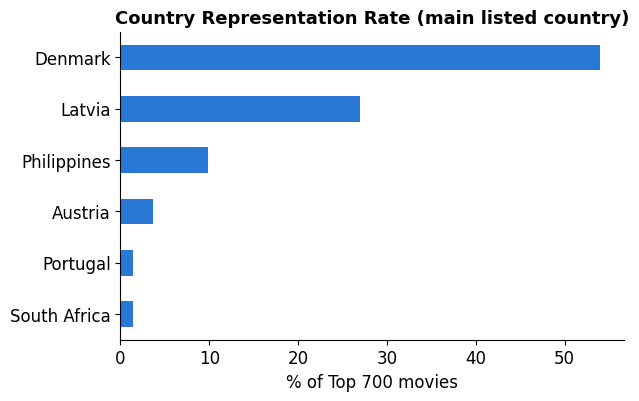

In [29]:
country_table.head(6)['Representation_Rate_%'].sort_values().plot(kind='barh', color=BLUE)
plt.title('Country Representation Rate (main listed country)')
plt.xlabel('% of Top 700 movies'); plt.ylabel('')
plt.savefig('figures/08_country.png', dpi=200, bbox_inches='tight')
plt.show()

**Observations :**
* **Denmark** is the main country for **54%** of movies, then Latvia (27%) and the Philippines (10%). The United
  States, home of most famous films, appears only twice.
* As shown in Step 7, these codes do **not** show where movies were made. **Country results should not be used for
  decisions** until IMDb fixes this column. This is an important data-quality finding.

## Step 16: Votes and runtime vs rating
### 16.1 Votes
A **scatter plot** shows one dot per movie. Each dot's position shows its votes and its rating.

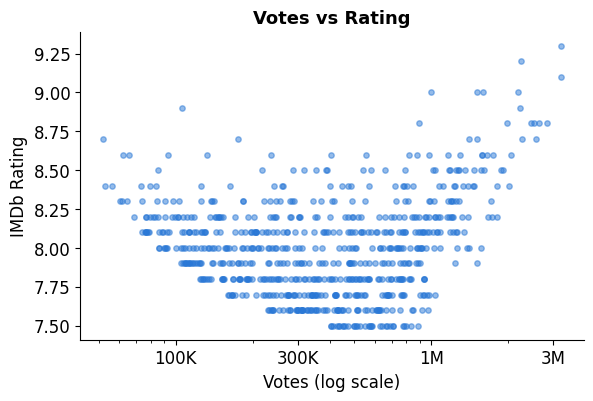

Correlation between Votes and Rating: 0.4


In [30]:
plt.scatter(df['Votes_K'], df['Rating'], color=BLUE, alpha=0.5, s=15)
plt.xscale('log')                         # log scale spreads out the many small vote counts
plt.xticks([100, 300, 1000, 3000], ['100K', '300K', '1M', '3M'])
plt.title('Votes vs Rating')
plt.xlabel('Votes (log scale)'); plt.ylabel('IMDb Rating')
plt.savefig('figures/09_votes_scatter.png', dpi=200, bbox_inches='tight')
plt.show()
print('Correlation between Votes and Rating:', round(df['Votes'].corr(df['Rating']), 2))

**Correlation** measures how two columns move together, from −1 to +1:
* +1 = when one goes up, the other always goes up
* 0 = no link
* −1 = when one goes up, the other goes down

Here it is **+0.40**: a moderate positive link. Let us check it by putting movies into vote groups.

In [31]:
df['Vote_Group'] = pd.cut(df['Votes'], bins=[0, 250_000, 500_000, 1_000_000, 4_000_000],
                          labels=['Under 250K', '250K-500K', '500K-1M', 'Over 1M'])
vote_table = df.groupby('Vote_Group').agg(Movies=('Title', 'count'), Avg_Rating=('Rating', 'mean'))
vote_table

,Movies,Avg_Rating
Vote_Group,,
Under 250K,232,8.04
250K-500K,187,7.86
500K-1M,195,7.91
Over 1M,86,8.40


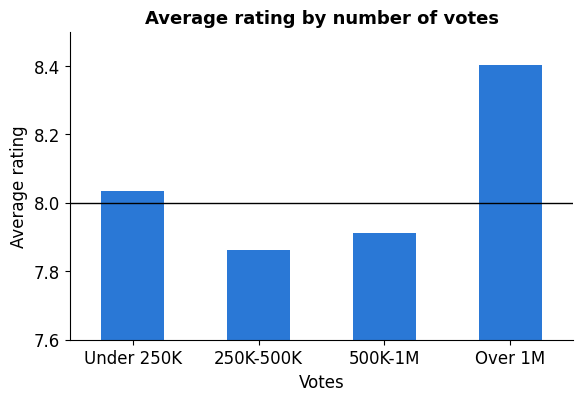

In [32]:
vote_table['Avg_Rating'].plot(kind='bar', color=BLUE, rot=0)
plt.ylim(7.6, 8.5)
plt.axhline(df['Rating'].mean(), color='black', linewidth=1)
plt.title('Average rating by number of votes')
plt.xlabel('Votes'); plt.ylabel('Average rating')
plt.savefig('figures/10_vote_groups.png', dpi=200, bbox_inches='tight')
plt.show()

**Observation: a "U" shape**
* Movies with **over 1 million votes** average **8.40**. These are the famous classics, and 79% of them are in the
  Top 100.
* Movies with **under 250K votes** also rate high (**8.04**), while the middle groups are lowest (7.86–7.91).
* **Why?** IMDb uses a *weighted* (Bayesian) formula. A movie with few votes is pulled down towards the average,
  so it can only enter the Top 700 if its rating is **very high**. That is why low-vote movies in the list are
  excellent, and why they are good **"hidden gems"** to recommend.

### 16.2 Hidden gems
Movies with a **high rating (8.2 or more)** but **fewer than 200,000 votes**:

In [33]:
df['Hidden_Gem'] = (df['Rating'] >= 8.2) & (df['Votes'] < 200_000)
print('Number of hidden gems:', df['Hidden_Gem'].sum())
df[df['Hidden_Gem']].sort_values('Rating', ascending=False)[['Title', 'Year', 'Genres', 'Rating', 'Votes']].head(10)

Number of hidden gems: 55


,Title,Year,Genres,Rating,Votes
177,Punjab '95,2026,Biography|Crime|Drama,8.90,105726
114,12th Fail,2023,Biography|Drama,8.70,175277
534,Kill Bill: The Whole Bloody Affair,2004,Action|Crime|Thriller,8.70,51964
301,Harakiri,1962,Drama|Mystery,8.60,93058
446,20 Days in Mariupol,2023,Documentary|War,8.60,65359
476,Rocketry: The Nambi Effect,2022,Biography|Drama,8.60,62428
216,Soorarai Pottru,2020,Drama,8.60,132475
380,Sita Ramam,2022,Action|Drama|Musical,8.50,84938
454,Demon Slayer: Kimetsu No Yaiba Infinity Castle,2025,Action|Adventure|Animation,8.40,79150
696,The Cove,2009,Biography|Crime|Documentary,8.40,52761


There are **55 hidden gems**, for example *12th Fail*, *Harakiri*, *Soorarai Pottru*, *Capernaum* and *Ikiru*.

### 16.3 Runtime

In [34]:
df['Runtime_Group'] = pd.cut(df['Runtime'], bins=[0, 100, 120, 140, 160, 400], right=False,
                             labels=['Under 100', '100-120', '120-140', '140-160', 'Over 160'])
runtime_table = df.groupby('Runtime_Group').agg(Movies=('Title', 'count'), Avg_Rating=('Rating', 'mean'))
print('Correlation between Runtime and Rating:', round(df['Runtime'].corr(df['Rating']), 2))
runtime_table

Correlation between Runtime and Rating: 0.24


,Movies,Avg_Rating
Runtime_Group,,
Under 100,102,7.97
100-120,202,7.93
120-140,200,7.97
140-160,105,8.06
Over 160,91,8.18


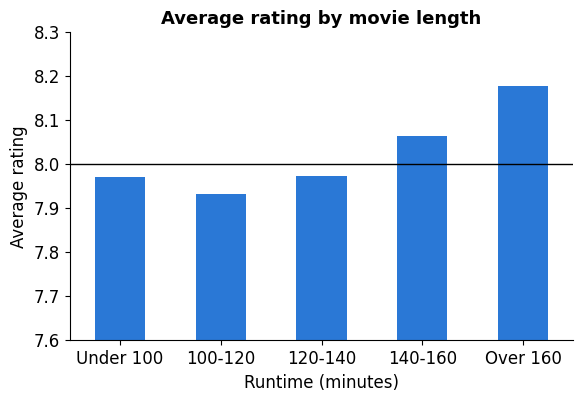

In [35]:
runtime_table['Avg_Rating'].plot(kind='bar', color=BLUE, rot=0)
plt.ylim(7.6, 8.3)
plt.axhline(df['Rating'].mean(), color='black', linewidth=1)
plt.title('Average rating by movie length')
plt.xlabel('Runtime (minutes)'); plt.ylabel('Average rating')
plt.savefig('figures/11_runtime_groups.png', dpi=200, bbox_inches='tight')
plt.show()

**Observation:** longer movies rate higher. Movies **over 160 minutes average 8.18**, while movies of 100–120
minutes average 7.93. The correlation is **+0.24** (a weak positive link). Long "epic" movies (*Lawrence of
Arabia*, *Schindler's List*, *The Godfather Part II*) are often among the best-loved.

## Step 17: Correlation heatmap
**What:** all correlations between the number columns in one coloured table.

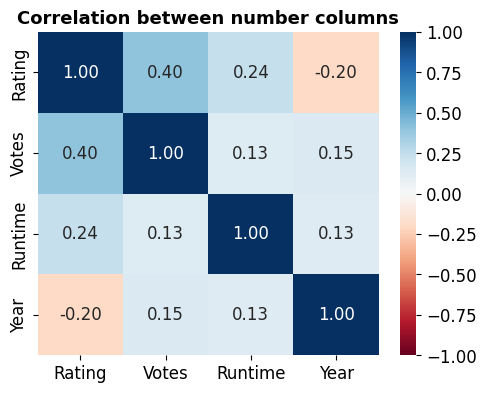

In [36]:
corr = df[['Rating', 'Votes', 'Runtime', 'Year']].corr()
plt.figure(figsize=(5.5, 4.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu', vmin=-1, vmax=1)
plt.title('Correlation between number columns')
plt.savefig('figures/12_correlation.png', dpi=200, bbox_inches='tight')
plt.show()

* **Rating & Votes: +0.40**: more votes, somewhat higher rating (driven by the famous classics).
* **Rating & Runtime: +0.24**: longer movies rate a little higher.
* **Rating & Year: −0.20**: newer movies rate a little lower.

## Step 18: Testing the hypotheses

**Tests used to find difference is real and not luck:**
* **t-test**: compares the averages of **two** groups.
* **ANOVA**: compares the averages of **more than two** groups.
* Both give a **p-value**. **If p-value < 0.05, the difference is probably real** (statistically significant).

For H1 and H2 we use the correlation from Step 16.

In [37]:
def t_test(group_a, group_b):
    result = stats.ttest_ind(group_a, group_b, equal_var=False)
    return group_a.mean(), group_b.mean(), result.pvalue

def p_text(p):
    return 'p < 0.0001' if p < 0.0001 else f'p = {p:.4f}'

# H3: Drama vs non-Drama
is_drama = df['Genres'].str.contains('Drama')
h3 = t_test(df[is_drama]['Rating'], df[~is_drama]['Rating'])

# H4: before 1980 vs 2000 onwards
h4 = t_test(df[df['Year'] < 1980]['Rating'], df[df['Year'] >= 2000]['Rating'])

# H5: directors with 4+ films vs 1 film
h5 = t_test(df[df['Director_Group'] == '4+ films']['Rating'], df[df['Director_Group'] == '1 film']['Rating'])

# H6: famous actor vs no famous actor
h6 = t_test(df[df['Has_Famous_Actor']]['Rating'], df[~df['Has_Famous_Actor']]['Rating'])

# H7: ANOVA across countries with at least 10 movies
groups = [g['Rating'] for country, g in df.groupby('Main_Country') if len(g) >= 10]
h7_p = stats.f_oneway(*groups).pvalue

for name, (a, b, p) in [('H3 Drama vs other', h3), ('H4 Old vs new', h4),
                        ('H5 Director 4+ vs 1', h5), ('H6 Famous actor vs not', h6)]:
    print(f'{name:<24} average {a:.2f} vs {b:.2f}   {p_text(p)}')
print(f'H7 Countries (ANOVA)     {p_text(h7_p)}')

H3 Drama vs other        average 8.03 vs 7.94   p = 0.0006
H4 Old vs new            average 8.14 vs 7.95   p < 0.0001
H5 Director 4+ vs 1      average 8.06 vs 7.98   p = 0.0065
H6 Famous actor vs not   average 8.00 vs 8.00   p = 0.7924
H7 Countries (ANOVA)     p = 0.0008


In [38]:
def verdict(a, b, p):
    # True only if group A is higher AND the p-value is below 0.05
    return 'True' if (a > b and p < 0.05) else 'False'

votes_corr = df['Votes'].corr(df['Rating'])
runtime_corr = df['Runtime'].corr(df['Rating'])
results = pd.DataFrame([
    ['H1', 'More votes → higher rating', f'Correlation {votes_corr:+.2f}; vote groups show a U shape', 'Partly true'],
    ['H2', 'Longer movies → higher rating', f'Correlation {runtime_corr:+.2f}; over 160 min average 8.18', 'True'],
    ['H3', 'Drama rates higher', f'{h3[0]:.2f} vs {h3[1]:.2f}, {p_text(h3[2])}', verdict(*h3)],
    ['H4', 'Older movies rate higher', f'{h4[0]:.2f} vs {h4[1]:.2f}, {p_text(h4[2])}', verdict(*h4)],
    ['H5', 'Directors with 4+ films rate higher', f'{h5[0]:.2f} vs {h5[1]:.2f}, {p_text(h5[2])}', verdict(*h5)],
    ['H6', 'Famous actors → higher rating', f'{h6[0]:.2f} vs {h6[1]:.2f}, {p_text(h6[2])}', verdict(*h6)],
    ['H7', 'Rating differs by country', f'ANOVA {p_text(h7_p)}',
     'True, but country data is unreliable' if h7_p < 0.05 else 'False'],
], columns=['#', 'Hypothesis', 'Evidence', 'Result'])
results

,#,Hypothesis,Evidence,Result
0,H1,More votes → higher rating,Correlation +0.40; vote groups show a U shape,Partly true
1,H2,Longer movies → higher rating,Correlation +0.24; over 160 min average 8.18,True
2,H3,Drama rates higher,"8.03 vs 7.94, p = 0.0006",True
3,H4,Older movies rate higher,"8.14 vs 7.95, p < 0.0001",True
4,H5,Directors with 4+ films rate higher,"8.06 vs 7.98, p = 0.0065",True
5,H6,Famous actors → higher rating,"8.00 vs 8.00, p = 0.7924",False
6,H7,Rating differs by country,ANOVA p = 0.0008,"True, but country data is unreliable"


## Step 19: Key insights and recommendations

### Key insights
1. **Votes matter, in a U shape.** The most-voted movies (1M+) are the true classics (8.40 average). Low-vote movies
   in the list are also excellent, because the weighted formula only lets them in with very high ratings.
2. **Serious genres rate highest.** War, Western, Biography and Drama lead. Horror, Thriller, Action and Comedy are lowest,
   but Sci-Fi, Fantasy and Adventure attract the most votes.
3. **Old classics rate highest.** 1930s–1960s movies average about 8.15. The busy 2000s–2010s average about 7.93.
4. **Long movies rate higher.** Over 160 minutes averages 8.18.
5. **Great directors repeat their success.** Directors with 4+ films are over 3 times more likely to reach the Top 100.
6. **Famous actors bring votes, not ratings.**
7. **The Country column has errors** and needs fixing.

### Recommendations for the IMDb Content Insights team
|   | Recommendation | Based on |
|---|---|---|
| 1 | Create a **"Hidden Gems"** section with the 55 high-rated, low-vote movies | Insight 1 |
| 2 | Make **director collections** (Nolan, Kurosawa, Leone, Wilder, Miyazaki) | Insight 5 |
| 3 | Promote **classic** and **War / Biography / Drama** movies as "timeless picks" | Insights 2 and 3 |
| 4 | Mark **2020s** movies as "rising" until their ratings settle | Step 12 |
| 5 | Use famous actors to **attract viewers**, not as a sign of quality | Insight 6 |
| 6 | **Fix the Country column** before any country-based reporting | Insight 7 |